# 01 — Dados: carga, qualidade e exposição

**Objetivo.** Transformar a base bruta (estipulantes, vidas, sinistros, prêmios) em uma tabela de experiência
auditável: exposição, óbitos e valores esperados pela tábua, e observados. Não precifica; entrega a base das
etapas seguintes.

**Convenções** (detalhes em `config/base.yaml` e `src/vgpricing/exposicao.py`):
- um segmento cobre de `data_inicio` a `data_fim`, inclusive; `data_fim` vazia significa em vigor;
- o ano-apólice vai do aniversário até a véspera do seguinte; o último pode ser parcial;
- a idade é a completa no início de cada pedaço de exposição; a tábua é a BR-EMSmt 2026 oficial;
- óbitos esperados de um pedaço com exposição $t$ (em anos): $E = q_x \, t$;
- observados são os sinistros **avisados** até a data de referência (o IBNR entra na Etapa 3).

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from vgpricing.graficos import estilo
estilo()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import chi2
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing.io import ler_pasta, ler_excel, salvar_pasta
from vgpricing.validacao import validar
from vgpricing.exposicao import exposicao_detalhada, experiencia

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, mapas = carregar_config("base", RAIZ), carregar_config("colunas", RAIZ)
DATA_REF = cfg["data_referencia"]
SAIDA = RAIZ / cfg["pasta_processados"]
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")      # achado documentado em data/external/README.md
    tabua = obter_tabua(cfg, RAIZ)
if tabua.placeholder:
    raise RuntimeError("Tábua oficial não carregada. Rode vgpricing.tabua.baixar_tabua_susep().")
print(f"Tábua: {tabua.nome} | sha256: {tabua.sha256[:16]}…")
pd.DataFrame(tabua.meta["conciliacao_ex"]).T

Tábua: BR-EMSmt-2026 | sha256: 45a1565083c77042…


,disponivel,max_dif_anos,idade_max_dif,consistente
M,True,0.0499,71,True
F,True,0.0494,59,True


A tábua é conferida a cada carga: hash do arquivo, $e_x$ publicado contra o $e_x$ calculado do $q_x$, e
mortalidade da tábua de morte maior que a de sobrevivência. No arquivo de 2026, a coluna $l_x$ está defasada
em uma idade e não é usada (detalhes em `data/external/README.md`).

## 1. Fonte dos dados

`FONTE = "sintetico"` gera a carteira de teste. Para dados reais, troque para `"excel"` (template em
`templates/`) ou `"pasta"` (parquet/CSV do banco) e ajuste só `config/colunas.yaml`. Daqui para frente, nada
neste notebook (nem nos seguintes) depende de os dados serem sintéticos.

In [2]:
FONTE = "sintetico"   # "sintetico" | "excel" | "pasta"

if FONTE == "sintetico":
    from vgpricing.sintetico import gerar_carteira, injetar_sujeira, tabelas_de_entrada
    cfg_s = carregar_config("sintetico", RAIZ)
    carteira = gerar_carteira(cfg_s, tabua)
    suja, verdade_sujeira = injetar_sujeira(carteira, cfg_s)
    salvar_pasta(tabelas_de_entrada(suja), RAIZ / "data/synthetic/entrada")
    # a verdade do gerador fica à parte, para o notebook 90 (validação do código)
    salvar_pasta({k: v for k, v in carteira.items() if k.startswith("verdade")} | {"verdade_sujeira": verdade_sujeira},
                 RAIZ / "data/synthetic/verdade")
    dados, problemas_leitura = ler_pasta(RAIZ / "data/synthetic/entrada", mapas, "parquet")
elif FONTE == "excel":
    dados, problemas_leitura = ler_excel(RAIZ / "data/raw/entrada.xlsx", mapas)
else:
    dados, problemas_leitura = ler_pasta(RAIZ / "data/raw", mapas, "parquet")

print("Problemas de conversão de tipo na leitura:", len(problemas_leitura))
pd.DataFrame({k: [len(v)] for k, v in dados.items()}, index=["linhas"])

Problemas de conversão de tipo na leitura: 0


,estipulantes,vidas,sinistros,premios
linhas,250,1486027,4203,2017


## 2. Qualidade de dados

Cada regra tem código, severidade e ação (`excluir`, `imputar` ou `sinalizar`). As regras rodam em ordem; um registro
excluído não é reavaliado pelas seguintes. Só a data de nascimento ausente é imputada (com indicador); o resto não é corrigido automaticamente: o log é o que vai para o time de
cadastro e para a auditoria.

In [3]:
res = validar(dados, cfg)
res.resumo()

,codigo,tabela,descricao,acao,severidade,registros
0,P01,premios,prêmio emitido difere de taxa × capital-ano em...,sinalizar,media,41
1,S01,sinistros,sinistro duplicado,excluir,alta,82
2,S02,sinistros,vida não encontrada na base de vidas (mantido ...,sinalizar,alta,41
3,S03,sinistros,ocorrência fora de período de cobertura na bas...,sinalizar,alta,23
4,S04,sinistros,aviso anterior à ocorrência,sinalizar,media,41
5,S06,sinistros,sinistro negado: fora da experiência,excluir,info,109
6,V01,vidas,linha duplicada,excluir,media,7393
7,V03,vidas,nascimento ausente (imputado: início menos a i...,imputar,media,1479
8,V04,vidas,idade de entrada impossível,excluir,alta,2957
9,V05,vidas,sexo ausente/inválido (esperado pela proporção...,sinalizar,media,255270


Sinistros com `S03` (ocorrência fora de cobertura na base limpa) normalmente são de vidas cujo segmento do
óbito foi excluído por erro de cadastro. Precisam de investigação antes de entrar na renovação.

In [4]:
res.excecoes[res.excecoes["codigo"] == "S03"].head()

,codigo,tabela,descricao,severidade,acao,id_linha,id_sinistro,id_estipulante,detalhe
280604,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,128,SIN0000129,EST0005,
280605,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,510,SIN0000520,EST0021,
280606,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,969,SIN0001004,EST0045,
280607,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,984,SIN0001020,EST0049,
280608,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,1000,SIN0001036,EST0049,


## 3. Exposição e experiência

Tabela por estipulante × ano-apólice. Quando o A/E é medido em valor, o peso de credibilidade de um grupo
não é o número de óbitos esperados, e sim o **número efetivo de óbitos**:

$$
n_{ef} = \frac{\left(\sum_v C_v\, q_v\, t_v\right)^2}{\sum_v C_v^2\, q_v\, t_v},
$$

em que $C_v$ é o capital da vida $v$. Com capital uniforme, $n_{ef}$ é igual aos óbitos esperados; com capital
concentrado em poucas vidas, é bem menor.

In [5]:
det = exposicao_detalhada(res.dados["vidas"], res.dados["estipulantes"], tabua, DATA_REF, cfg["exposicao"]["dias_por_ano"])
xp = experiencia(det, res.dados["sinistros"], res.dados["estipulantes"], DATA_REF)
tot = xp[["vidas_ano", "capital_ano", "obitos_esperados", "obitos_observados", "valor_esperado", "valor_observado"]].sum()
pd.Series({"estipulantes": xp["id_estipulante"].nunique(), "vidas-ano": tot["vidas_ano"],
           "capital-ano (R$ bi)": tot["capital_ano"] / 1e9, "óbitos esperados": tot["obitos_esperados"],
           "óbitos observados (avisados)": tot["obitos_observados"],
           "A/E óbitos": tot["obitos_observados"] / tot["obitos_esperados"],
           "A/E valor": tot["valor_observado"] / tot["valor_esperado"]}).to_frame("carteira")

,carteira
estipulantes,250.0000
vidas-ano,"1,982,053.4237"
capital-ano (R$ bi),177.4388
óbitos esperados,"3,717.4892"
óbitos observados (avisados),"4,012.0000"
A/E óbitos,1.0792
A/E valor,1.0198


### Dados faltantes: sexo e data de nascimento

Na vida real é comum o censo de um grupo vir **sem sexo** (às vezes o grupo inteiro) ou com nascimentos ausentes.
Tratamento adotado:
- **Sexo ausente:** a vida fica na base, e o esperado usa a mistura $q = p\,q^{M} + (1 - p)\,q^{F}$, com $p$ a proporção de
  homens do nível mais fino que tiver dados (mesmo grupo e faixa etária, o grupo, a seção CNAE e a faixa, a carteira).
  É exata para o número esperado de óbitos, que é linear em $p$. Nas células da taxa manual, sexo ausente é o nível
  "ND", testado como qualquer fator (a ausência pode carregar informação).
- **Nascimento ausente:** imputado pela idade de entrada mediana do grupo, com indicador (`nascimento_imputado`).
  Excluir a vida perderia exposição e enviesaria o A/E.

O teste: na carteira sintética, alguns grupos mandam o censo sem sexo, com mais frequência nas atividades de
maioria masculina (indústria, construção, transporte). Comparam-se os esperados desses grupos pela média 50/50, pela
mistura e pelo sexo verdadeiro (conhecido só porque a carteira é sintética).

In [6]:
v = res.dados["vidas"]
sem = v.groupby("id_estipulante")["sexo"].apply(lambda s: s.isna().all())
grupos_sem = sem[sem].index
vs = v[v["id_estipulante"].isin(grupos_sem)]
# a proporção de homens vem dos outros grupos da carteira: a exposição é calculada na carteira inteira
det_mix = det[det["id_estipulante"].isin(grupos_sem)]                                         # mistura (padrão)
det_mix = det_mix.copy()
verdade_sexo = carteira["vidas"].set_index("id_linha")["sexo"]
det_v = exposicao_detalhada(vs.assign(sexo=vs["id_linha"].map(verdade_sexo)), res.dados["estipulantes"], tabua, DATA_REF)
E_50 = (tabua.q(det_mix["idade"].to_numpy(), np.array([None] * len(det_mix), dtype=object)) * det_mix["exposicao"]).sum()
secoes = res.dados["estipulantes"].set_index("id_estipulante").loc[grupos_sem, "cnae_secao"].value_counts().to_dict()
print(f"Grupos sem sexo no censo: {len(grupos_sem)} (seções: {secoes}); vidas com sexo ausente na base: {int(v['sexo'].isna().sum()):,}")
pd.Series({"esperados pelo sexo verdadeiro": det_v["obitos_esperados"].sum(),
           "média 50/50": E_50, "mistura pela proporção de homens": det_mix["obitos_esperados"].sum()}).to_frame("óbitos esperados")

Grupos sem sexo no censo: 50 (seções: {'C': 15, 'G': 9, 'F': 8, 'H': 7, 'K': 4, 'Q': 3, 'O': 1, 'N': 1, 'M': 1, 'P': 1}); vidas com sexo ausente na base: 254,182


,óbitos esperados
esperados pelo sexo verdadeiro,745.8104
média 50/50,712.0011
mistura pela proporção de homens,745.0725


### Concentração de capital: número efetivo contra óbitos esperados

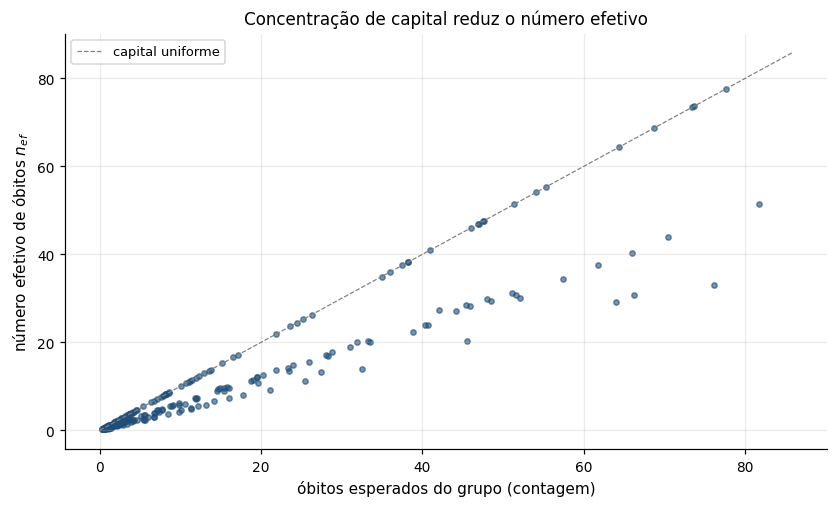

count   250.0000
mean      0.7404
std       0.2176
min       0.3880
25%       0.5942
50%       0.6438
75%       1.0000
max       1.0000
dtype: float64

In [7]:
grp = xp.groupby("id_estipulante")[["obitos_esperados", "valor_esperado", "soma_c2q"]].sum()
grp["n_efetivo"] = grp["valor_esperado"] ** 2 / grp["soma_c2q"]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(grp["obitos_esperados"], grp["n_efetivo"], s=12, alpha=0.6, color="#1f4e79")
lim = grp["obitos_esperados"].max() * 1.05
ax.plot([0, lim], [0, lim], color="grey", ls="--", lw=0.8, label="capital uniforme")
ax.set_xlabel("óbitos esperados do grupo (contagem)"); ax.set_ylabel(r"número efetivo de óbitos $n_{ef}$")
ax.set_title("Concentração de capital reduz o número efetivo"); ax.legend(); plt.show()
(grp["n_efetivo"] / grp["obitos_esperados"]).describe()

Grupos abaixo da diagonal têm o capital concentrado em poucas vidas: a sinistralidade em R$ deles oscila
mais do que o número de vidas sugere, e a credibilidade precisa refletir isso.

## 4. Conciliação de prêmio

In [8]:
p = res.dados.get("premios")
if p is not None and "dif_rel" in p:
    lim = cfg["validacao"]["tolerancia_conciliacao_premio"]
    print(f"Períodos com divergência acima de {lim:.0%}: {int((p['dif_rel'].abs() > lim).sum())} de {len(p)}")

Períodos com divergência acima de 2%: 41 de 2017


Divergências vêm de registros excluídos na validação (o prêmio foi faturado sobre a base suja). Afastados
continuam faturados e entram na conciliação.

## 5. Saídas (entrada do estudo de experiência, 02)

In [9]:
SAIDA.mkdir(parents=True, exist_ok=True)
res.excecoes.to_csv(SAIDA / "log_excecoes.csv", index=False)
xp.to_parquet(SAIDA / "experiencia_estipulante_ano.parquet", index=False)
salvar_pasta(res.dados, SAIDA / "limpo")
sorted(str(x.relative_to(SAIDA)) for x in SAIDA.rglob("*") if x.is_file())

['cache/.gitignore',
 'cache/__main__--tmp-ipykernel-1448346431/uma_reamostra/008bcf6bce0bcd6ff48f2bf9381fab36/metadata.json',
 'cache/__main__--tmp-ipykernel-1448346431/uma_reamostra/008bcf6bce0bcd6ff48f2bf9381fab36/output.pkl',
 'cache/__main__--tmp-ipykernel-1448346431/uma_reamostra/036744d3d0b5e83b419dbbcc40db0018/metadata.json',
 'cache/__main__--tmp-ipykernel-1448346431/uma_reamostra/036744d3d0b5e83b419dbbcc40db0018/output.pkl',
 'cache/__main__--tmp-ipykernel-1448346431/uma_reamostra/03b0d562b39e2cad00bc8160e5bc9038/metadata.json',
 'cache/__main__--tmp-ipykernel-1448346431/uma_reamostra/03b0d562b39e2cad00bc8160e5bc9038/output.pkl',
 'cache/__main__--tmp-ipykernel-1448346431/uma_reamostra/0440c8bda074947eed1ad54ad5fcb881/metadata.json',
 'cache/__main__--tmp-ipykernel-1448346431/uma_reamostra/0440c8bda074947eed1ad54ad5fcb881/output.pkl',
 'cache/__main__--tmp-ipykernel-1448346431/uma_reamostra/07b3db6130b65ddd1af4e17b63488a08/metadata.json',
 'cache/__main__--tmp-ipykernel-14483

## Limitações
- Com a carteira sintética, os níveis de A/E refletem as hipóteses do gerador (`config/sintetico.yaml`).
- O esperado linear $q_x\,t$ superestima levemente em pedaços longos e idades altas; desprezível em idades
  ativas.
- Sexo ausente: mistura pela proporção de homens do perfil (seção 2). Antes usava a média masculino/feminino da tábua, sinalizado no log (V05).
- Observados ainda sem IBNR: o A/E dos anos recentes está subestimado até a Etapa 3.